In [16]:
import sys, os, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import importlib, subprocess
needed = ["tensorflow", "numpy", "pandas", "matplotlib", "seaborn",
          "scikit-learn", "lime", "shap", "opencv-python-headless", "Pillow"]
missing = []
for pkg in needed:
    name = pkg.split("==")[0].split("-")[0].replace("opencv_python_headless","cv2").replace("scikit","sklearn")
    try:
        importlib.import_module("cv2" if name=="cv2" else name)
    except Exception:
        missing.append(pkg)
if missing:
    print("Installing:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing)
else:
    print("All dependencies already installed.")

Installing: ['opencv-python-headless', 'Pillow']


In [19]:
import numpy as np, random, tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers, models, callbacks, optimizers, metrics
from sklearn.utils.class_weight import compute_class_weight

# ---------- CONFIG ----------
DATA_DIR    = Path("./Breast Cancer Patients MRI")
IMG_SIZE    = (64, 64)          # keep your size
BATCH_SIZE  = 32                # 10 is very noisy for BN; go 32 if RAM allows
EPOCHS      = 40
LR          = 3e-4              # <-- was 1e-2. This alone fixes most of it.
SEED        = 42
USE_CLASS_WEIGHTS = True        # <-- new: fixes the majority-class collapse
LABEL_SMOOTHING   = 0.05        # <-- new: small regularizer
OUT_DIR     = Path("./outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)
XAI_DIR     = OUT_DIR / "xai";   XAI_DIR.mkdir(exist_ok=True)
MODEL_PATH  = OUT_DIR / "breast_cnn.keras"

# Wipe the bad checkpoint from the previous run
if MODEL_PATH.exists():
    MODEL_PATH.unlink(); print("Deleted stale checkpoint:", MODEL_PATH)

np.random.seed(SEED); tf.random.set_seed(SEED); random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF: 2.19.1 | GPU: []


In [20]:
ALIASES = {
    "train": ["train","Train","TRAIN","training","Training"],
    "val":   ["val","Val","VAL","valid","validation","Validation"],
    "test":  ["test","Test","TEST","testing","Testing"],
}

def find_splits(root):
    m = {}
    for split, names in ALIASES.items():
        for n in names:
            p = root / n
            if p.is_dir():
                m[split] = p; break
    return m

splits = find_splits(DATA_DIR)
print("Detected splits:", {k: str(v) for k, v in splits.items()})

if "train" not in splits:
    # Single folder with class subdirectories
    print("Using DATA_DIR with validation_split=0.2 (no explicit splits).")
    train_ds = image_dataset_from_directory(
        DATA_DIR, labels="inferred", label_mode="categorical",
        color_mode="rgb", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=True, seed=SEED, validation_split=0.2, subset="training")
    val_ds = image_dataset_from_directory(
        DATA_DIR, labels="inferred", label_mode="categorical",
        color_mode="rgb", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=True, seed=SEED, validation_split=0.2, subset="validation")
    test_ds = val_ds
    class_names = train_ds.class_names
else:
    train_ds = image_dataset_from_directory(
        splits["train"], labels="inferred", label_mode="categorical",
        color_mode="rgb", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=True, seed=SEED)
    class_names = train_ds.class_names

    val_ds  = (image_dataset_from_directory(
                  splits["val"], labels="inferred", label_mode="categorical",
                  color_mode="rgb", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
                  shuffle=False)
               if "val" in splits else None)

    test_ds = (image_dataset_from_directory(
                  splits["test"], labels="inferred", label_mode="categorical",
                  color_mode="rgb", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
                  shuffle=False)
               if "test" in splits else val_ds)

NUM_CLASSES = len(class_names)
print("Classes:", class_names, "| num_classes =", NUM_CLASSES)

Detected splits: {'train': 'Breast Cancer Patients MRI\\train', 'val': 'Breast Cancer Patients MRI\\validation'}
Found 1400 files belonging to 2 classes.
Found 680 files belonging to 2 classes.
Classes: ['Healthy', 'Sick'] | num_classes = 2


In [22]:
def normalize(ds):
    return ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
                  num_parallel_calls=AUTOTUNE)

train_n = normalize(train_ds)
val_n   = normalize(val_ds)  if val_ds  is not None else None
test_n  = normalize(test_ds) if test_ds is not None else None

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augment")

train_ready = (train_n
               .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
               .prefetch(AUTOTUNE))
val_ready   = val_n.prefetch(AUTOTUNE)   if val_n  is not None else None
test_ready  = test_n.prefetch(AUTOTUNE)  if test_n is not None else None

In [23]:
# def normalize(ds):
#     return ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
#                   num_parallel_calls=AUTOTUNE)

# train_n = normalize(train_ds)
# val_n   = normalize(val_ds)  if val_ds  is not None else None
# test_n  = normalize(test_ds) if test_ds is not None else None

# augment = tf.keras.Sequential([
#     layers.RandomFlip("horizontal"),
#     layers.RandomRotation(0.08),
#     layers.RandomZoom(0.1),
#     layers.RandomContrast(0.1),
# ], name="augment")

# train_ready = (train_n
#                .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
#                .prefetch(AUTOTUNE))
# val_ready   = val_n.prefetch(AUTOTUNE)   if val_n  is not None else None
# test_ready  = test_n.prefetch(AUTOTUNE)  if test_n is not None else None

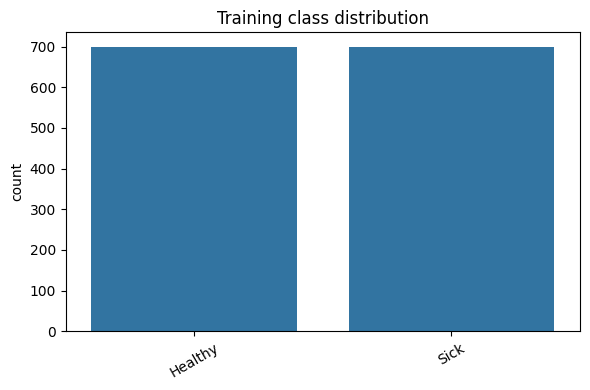

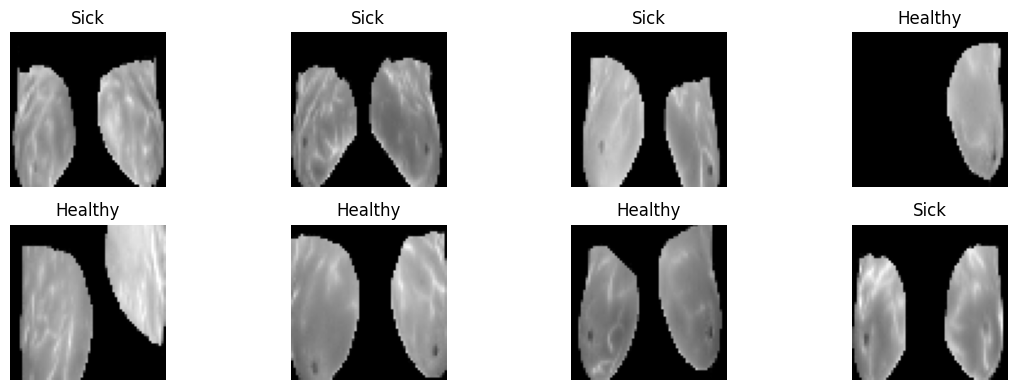

In [24]:
# Class distribution
labels_all = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in train_n])
plt.figure(figsize=(6, 4))
sns.countplot(x=labels_all)
plt.xticks(range(NUM_CLASSES), class_names, rotation=30)
plt.title("Training class distribution")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_dist.png", dpi=120); plt.show()

# Sample images
plt.figure(figsize=(12, 4))
for imgs, labs in train_n.take(1):
    for i in range(min(8, len(imgs))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(imgs[i].numpy()); plt.title(class_names[int(tf.argmax(labs[i]))])
        plt.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "samples.png", dpi=120); plt.show()

In [25]:
def build_cnn(input_shape=(64, 64, 3), num_classes=2):
    inp = layers.Input(shape=input_shape, name="input")
    x = inp
    for i, f in enumerate([32, 64, 128, 256], start=1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv{i}_1")(x)
        x = layers.BatchNormalization(name=f"bn{i}_1")(x)
        x = layers.Activation("relu", name=f"relu{i}_1")(x)
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv{i}_2")(x)
        x = layers.BatchNormalization(name=f"bn{i}_2")(x)
        x = layers.Activation("relu", name=f"relu{i}_2")(x)
        x = layers.MaxPooling2D(2, name=f"pool{i}")(x)
        if i >= 2:
            x = layers.Dropout(0.15, name=f"drop_conv{i}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.4, name="drop1")(x)
    x = layers.Dense(128, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.3, name="drop2")(x)
    out = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return models.Model(inp, out, name="breast_cnn_64")

model = build_cnn(IMG_SIZE + (3,), NUM_CLASSES)
model.summary()
LAST_CONV_LAYER = "conv4_2"     # <-- changed for the shallower net

Model: "breast_cnn_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)                   │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_1 (Conv2D)                     │ (None, 64, 64, 32)          │             864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn1_1 (BatchNormalization)           │ (None, 64, 64, 32)          │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu1_1 (Activation)                 │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_2 (Conv2D)                     │ (None, 64, 64, 32)          │           9,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn1_2 (BatchNormalization)           │ (None, 64, 64, 32)          │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu1_2 (Activation)                 │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2_1 (Conv2D)                     │ (None, 32, 32, 64)          │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn2_1 (BatchNormalization)           │ (None, 32, 32, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu2_1 (Activation)                 │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2_2 (Conv2D)                     │ (None, 32, 32, 64)          │          36,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn2_2 (BatchNormalization)           │ (None, 32, 32, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu2_2 (Activation)                 │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_conv2 (Dropout)                 │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3_1 (Conv2D)                     │ (None, 16, 16, 128)         │          73,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn3_1 (BatchNormalization)           │ (None, 16, 16, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu3_1 (Activation)                 │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3_2 (Conv2D)                     │ (None, 16, 16, 128)         │         147,456 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn3_2 (BatchNormalization)           │ (None, 16, 16, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 1,208,290 (4.61 MB)

 Trainable params: 1,206,370 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [26]:
# --- class weights (computed from training labels) ---
if USE_CLASS_WEIGHTS:
    y_train_idx = np.concatenate([np.argmax(y.numpy(), 1) for _, y in train_n])
    cw = compute_class_weight("balanced",
                              classes=np.arange(NUM_CLASSES),
                              y=y_train_idx)
    class_weight = {i: float(w) for i, w in enumerate(cw)}
    print("class_weight:", class_weight,
          "| train counts:", np.bincount(y_train_idx).tolist())
else:
    class_weight = None

model.compile(
    optimizer=optimizers.Adam(LR, clipnorm=1.0),   # <-- gradient clipping stabilizes BN
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
    metrics=["accuracy", metrics.AUC(name="auc")],
)

cbs = [
    callbacks.ModelCheckpoint(str(MODEL_PATH), monitor="val_auc",
                              mode="max", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_auc", mode="max",
                            patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                patience=3, min_lr=1e-6, verbose=1),
]

history = model.fit(
    train_ready,
    validation_data=val_ready,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=cbs,
    verbose=1,
)

class_weight: {0: 1.0, 1: 1.0} | train counts: [700, 700]
Epoch 1/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.5565 - auc: 0.5817 - loss: 0.9548
Epoch 1: val_auc improved from None to 0.51703, saving model to outputs\breast_cnn.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 333ms/step - accuracy: 0.5893 - auc: 0.6231 - loss: 0.8363 - val_accuracy: 0.5000 - val_auc: 0.5170 - val_loss: 0.8214 - learning_rate: 3.0000e-04
Epoch 2/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 0.6578 - auc: 0.7124 - loss: 0.6768
Epoch 2: val_auc did not improve from 0.51703
44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 298ms/step - accuracy: 0.6664 - auc: 0.7278 - loss: 0.6494 - val_accuracy: 0.5000 - val_auc: 0.4815 - val_loss: 1.2155 - learning_rate: 3.0000e-04
Epoch 3/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.6850 - auc: 0.7640 - loss: 0.6131
Epoch 3: val_auc did not improve from 0.51703
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 314ms/step - accuracy: 0.7000 - auc: 0.7742 - loss: 0.5957 - val_accuracy:

In [27]:
hist = history.history
print(f"final train loss: {hist['loss'][-1]:.3f}")
print(f"final val   loss: {hist['val_loss'][-1]:.3f}")
print(f"final val   auc : {hist['val_auc'][-1]:.3f}")

# Healthy run should show val_loss DROPPING below 0.693 and val_auc RISING above 0.55.
# If val_loss is still ~0.69 after 8 epochs → class imbalance is worse than 70/30,
# or DATA_DIR class folders are mislabeled. Check:
for name in class_names:
    p = (Path(splits["train"]) / name) if "train" in splits else (DATA_DIR / name)
    print(f"{name:>20s}: {len(list(p.glob('*')))} images")

final train loss: 0.330
final val   loss: 0.618
final val   auc : 0.862
             Healthy: 700 images
                Sick: 700 images


              precision    recall  f1-score   support

     Healthy       0.86      0.97      0.91       340
        Sick       0.97      0.84      0.90       340

    accuracy                           0.90       680
   macro avg       0.91      0.90      0.90       680
weighted avg       0.91      0.90      0.90       680



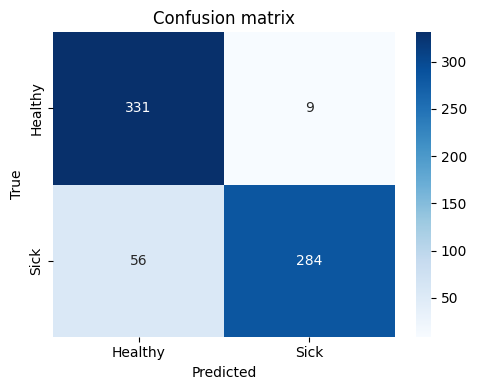

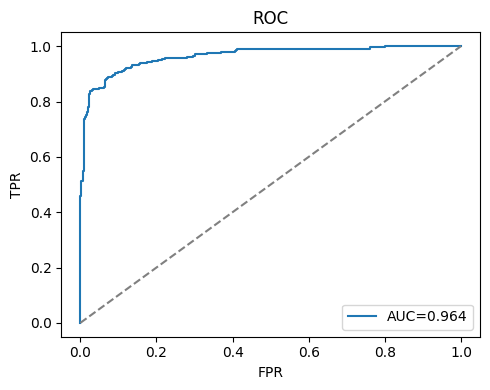

In [28]:
y_true, y_prob = [], []
for x, y in test_n:
    y_prob.append(model.predict(x, verbose=0))
    y_true.append(y.numpy())
y_true = np.concatenate(y_true); y_prob = np.concatenate(y_prob)
y_true_i = y_true.argmax(1); y_pred_i = y_prob.argmax(1)

print(classification_report(y_true_i, y_pred_i, target_names=class_names))

cm = confusion_matrix(y_true_i, y_pred_i)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=120); plt.show()

# ROC
plt.figure(figsize=(5, 4))
if NUM_CLASSES == 2:
    fpr, tpr, _ = roc_curve(y_true_i, y_prob[:, 1])
    plt.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.3f}")
else:
    yt = label_binarize(y_true_i, classes=range(NUM_CLASSES))
    for i, n in enumerate(class_names):
        fpr, tpr, _ = roc_curve(yt[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, label=f"{n} ({auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC"); plt.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "roc.png", dpi=120); plt.show()

In [29]:
def prep(img):
    img = np.asarray(img, dtype=np.float32)
    if img.max() > 1.5: img = img / 255.0
    if img.ndim == 2: img = np.stack([img]*3, -1)
    return np.clip(img, 0, 1)

def prep_input(img, size=IMG_SIZE):
    x = prep(img)
    x = tf.image.resize(x, size).numpy()
    return x[None].astype(np.float32)

def overlay(img, heat, alpha=0.45, cmap="jet"):
    img = prep(img)
    if img.ndim == 4: img = img[0]
    h, w = img.shape[:2]
    heat = tf.image.resize(heat[..., None], (h, w)).numpy()[..., 0]
    heat = np.clip(heat, 0, 1)
    colored = plt.get_cmap(cmap)(heat)[..., :3]
    return np.clip((1 - alpha) * img + alpha * colored, 0, 1)

def grab_batch(ds, n=1):
    for x, y in ds.take(1):
        return x.numpy()[:n], y.numpy()[:n]

# One demo sample
Xs, ys = grab_batch(test_n, 1)
sample_img   = Xs[0]
sample_input = prep_input(sample_img)
true_idx     = int(ys[0].argmax())
pred_probs   = model.predict(sample_input, verbose=0)[0]
pred_idx     = int(pred_probs.argmax())
print(f"True: {class_names[true_idx]} | Pred: {class_names[pred_idx]} "
      f"({pred_probs[pred_idx]:.3f})")

True: Healthy | Pred: Healthy (0.922)


In [30]:
def _grad_model(model, layer_name):
    return tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output],
    )

def grad_cam(model, x, layer_name=LAST_CONV_LAYER, class_idx=None):
    gm = _grad_model(model, layer_name)
    with tf.GradientTape() as tape:
        conv, preds = gm(x, training=False)
        if class_idx is None: class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.reduce_sum(conv[0] * w, axis=-1)
    heat = tf.nn.relu(heat)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy()

def grad_cam_pp(model, x, layer_name=LAST_CONV_LAYER, class_idx=None):
    gm = _grad_model(model, layer_name)
    with tf.GradientTape(persistent=True) as t3:
        t3.watch([])
        with tf.GradientTape(persistent=True) as t2:
            with tf.GradientTape() as t1:
                conv, preds = gm(x, training=False)
                if class_idx is None: class_idx = int(tf.argmax(preds[0]))
                score = preds[:, class_idx]
            g1 = t1.gradient(score, conv)
        g2 = t2.gradient(g1, conv)
    g3 = t3.gradient(g2, conv)
    eps = 1e-7
    alpha = g2 / (2 * g2 + conv * g3 + eps)
    w = tf.reduce_sum(tf.nn.relu(alpha) * tf.nn.relu(g1), axis=(0, 1))
    heat = tf.reduce_sum(w[None, None] * conv, axis=-1)[0]
    heat = tf.nn.relu(heat)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy()

def vanilla_saliency(model, x, class_idx=None):
    xt = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        tape.watch(xt)
        preds = model(xt, training=False)
        if class_idx is None: class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    g = tape.gradient(score, xt)
    sal = tf.reduce_max(tf.abs(g), axis=-1)[0].numpy()
    return (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)

def integrated_gradients(model, x, class_idx=None, baseline=None, steps=50):
    if baseline is None: baseline = np.zeros_like(x)
    xt = tf.convert_to_tensor(x); bt = tf.convert_to_tensor(baseline)
    if class_idx is None:
        class_idx = int(tf.argmax(model(xt, training=False)[0]))
    alphas = tf.linspace(0.0, 1.0, steps + 1)[1:]
    total = tf.zeros_like(xt)
    for a in alphas:
        interp = bt + a * (xt - bt)
        with tf.GradientTape() as tape:
            tape.watch(interp)
            score = model(interp, training=False)[:, class_idx]
        total += tape.gradient(score, interp)
    avg = total / tf.cast(steps, total.dtype)
    ig = tf.reduce_sum((xt - bt) * avg, axis=-1)[0].numpy()
    return (ig - ig.min()) / (ig.max() - ig.min() + 1e-8)

def smoothgrad(model, x, class_idx=None, n=25, noise=0.1):
    sal = np.zeros(x.shape[1:3], dtype=np.float32)
    for _ in range(n):
        xn = np.clip(x + noise * np.random.randn(*x.shape).astype(np.float32), 0, 1)
        sal += vanilla_saliency(model, xn, class_idx)
    sal /= n
    return (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)

In [31]:
@tf.custom_gradient
def _guided_relu(x):
    y = tf.nn.relu(x)
    def grad(dy):
        return dy * tf.cast((x > 0) & (dy > 0), dy.dtype)
    return y, grad

def build_guided(model):
    new_layers = []
    for lyr in model.layers:
        if isinstance(lyr, layers.InputLayer):
            continue
        cfg = lyr.get_config()
        if isinstance(lyr, layers.Activation) and cfg.get("activation") == "relu":
            new_layers.append(layers.Activation(_guided_relu, name=cfg["name"]))
        else:
            new_layers.append(lyr.__class__.from_config(cfg))
    inp = layers.Input(shape=model.input_shape[1:], name="guided_in")
    x = inp
    for lyr in new_layers:
        x = lyr(x)
    gb = tf.keras.Model(inp, x, name="guided")
    gb.set_weights(model.get_weights())
    return gb

_GUIDED = build_guided(model)

def guided_backprop(model, x, class_idx=None):
    xt = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        tape.watch(xt)
        preds = _GUIDED(xt, training=False)
        if class_idx is None: class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    g = tape.gradient(score, xt)
    sal = tf.reduce_max(tf.abs(g), axis=-1)[0].numpy()
    return (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)

In [36]:
def score_cam(model, x, layer_name=LAST_CONV_LAYER, class_idx=None, n_channels=32):
    gm = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output],
    )
    conv, preds = gm(x, training=False)
    conv = conv[0].numpy()                          # (h, w, C)
    if class_idx is None:
        class_idx = int(tf.argmax(preds[0]))

    C = conv.shape[-1]
    if n_channels and n_channels < C:
        keep = np.argsort(conv.mean(axis=(0, 1)))[-n_channels:]
        conv = conv[..., keep]
        C = len(keep)

    H, W = x.shape[1:3]

    # FIX 1: resize the 3-D (h,w,C) map directly -> (H,W,C).
    # Do NOT add [..., None] — that turns it into (h,w,C,1) and breaks resize.
    masks = tf.image.resize(conv, (H, W)).numpy()   # (H, W, C)

    scores = np.zeros(C, dtype=np.float32)
    for c in range(C):
        # FIX 2: broadcast (H,W) mask up to (1,H,W,1) so it matches x=(1,H,W,3)
        m = masks[..., c][None, ..., None]
        masked = x * m
        scores[c] = float(model(masked, training=False).numpy()[0, class_idx])

    scores = scores / (scores.max() + 1e-8)
    heat = np.sum(masks * scores[None, None, :], axis=-1)   # (H, W)
    heat = np.maximum(heat, 0)
    heat = heat / (heat.max() + 1e-8)
    return heat

def occlusion(model, x, class_idx=None, patch=32, stride=16):
    if class_idx is None:
        class_idx = int(tf.argmax(model(x, training=False)[0]))
    base = model(x, training=False).numpy()[0, class_idx]
    H, W = x.shape[1:3]
    heat = np.zeros((H, W)); counts = np.zeros((H, W))
    for y in range(0, H - patch + 1, stride):
        for xx in range(0, W - patch + 1, stride):
            o = x.copy(); o[:, y:y+patch, xx:xx+patch, :] = 0
            p = model(o, training=False).numpy()[0, class_idx]
            heat[y:y+patch, xx:xx+patch] += (base - p)
            counts[y:y+patch, xx:xx+patch] += 1
    counts[counts == 0] = 1; heat /= counts
    heat = np.maximum(heat, 0)
    return heat / (heat.max() + 1e-8)

  0%|          | 0/800 [00:00<?, ?it/s]

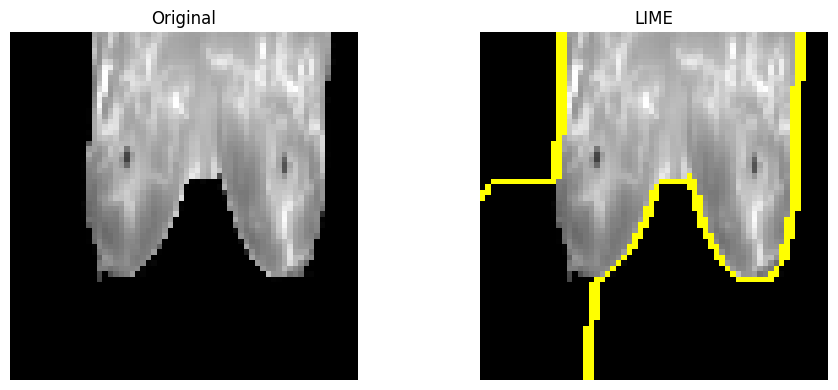

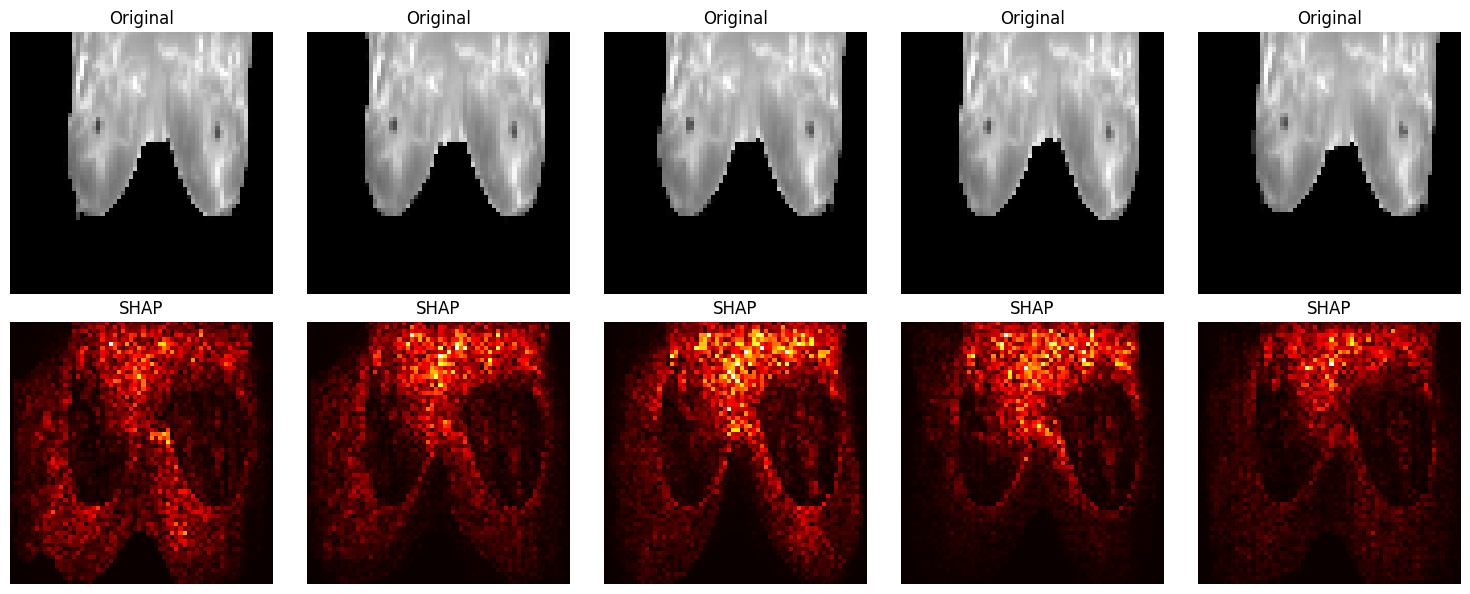

In [37]:
# Cell 14 (replacement) — LIME + SHAP with robust imports and shape handling
import shap                                     # <-- the missing import
from lime import lime_image
from skimage.segmentation import mark_boundaries

def run_lime(sample_img, n_samples=800):
    explainer = lime_image.LimeImageExplainer()
    img = prep(sample_img)
    exp = explainer.explain_instance(
        img.astype(np.double),
        lambda z: model.predict(z.astype(np.float32), verbose=0),
        top_labels=1, hide_color=0, num_samples=n_samples,
    )
    temp, mask = exp.get_image_and_mask(
        exp.top_labels[0], positive_only=True, num_features=10, hide_rest=False)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(img); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(mark_boundaries(temp, mask)); ax[1].set_title("LIME"); ax[1].axis("off")
    plt.tight_layout(); plt.savefig(XAI_DIR / "lime.png", dpi=120); plt.show()


def run_shap(n_bg=30, n_test=5):
    # ---- gather background (train) and test images, capped by batch size ----
    bg = np.concatenate([x.numpy() for x, _ in train_n.take(3)])[:n_bg]
    n_test = int(min(n_test, BATCH_SIZE))       # <-- guard against batch overflow
    te, _ = grab_batch(test_n, n_test)

    # ---- explainer ----
    explainer = shap.GradientExplainer(model, bg)
    sv = explainer.shap_values(te, nsamples=100)

    # ---- normalise shape to (n_test, H, W, C) for one class ----
    if isinstance(sv, list):                    # list of arrays, one per class
        cls = int(model.predict(te[:1], verbose=0)[0].argmax())
        sv = sv[cls]
    else:
        sv = np.asarray(sv)
        if sv.ndim == 5:                        # (n, H, W, C, n_classes)
            cls = int(model.predict(te[:1], verbose=0)[0].argmax())
            sv = sv[..., cls]
        # else already (n, H, W, C) — leave it

    # ---- aggregate across RGB channels → (n, H, W) ----
    sv_img = np.abs(sv).sum(-1)
    sv_img = sv_img - sv_img.min()
    sv_img = sv_img / (sv_img.max() + 1e-8)

    # ---- plot ----
    fig, axes = plt.subplots(2, n_test, figsize=(3 * n_test, 6))
    if n_test == 1:
        axes = np.array([[axes[0]], [axes[1]]])   # keep 2-D indexing
    for i in range(n_test):
        axes[0, i].imshow(prep(te[i]))
        axes[0, i].set_title("Original"); axes[0, i].axis("off")
        axes[1, i].imshow(sv_img[i], cmap="hot")
        axes[1, i].set_title("SHAP"); axes[1, i].axis("off")
    plt.tight_layout()
    plt.savefig(XAI_DIR / "shap.png", dpi=120)
    plt.show()

run_lime(sample_img)
run_shap()

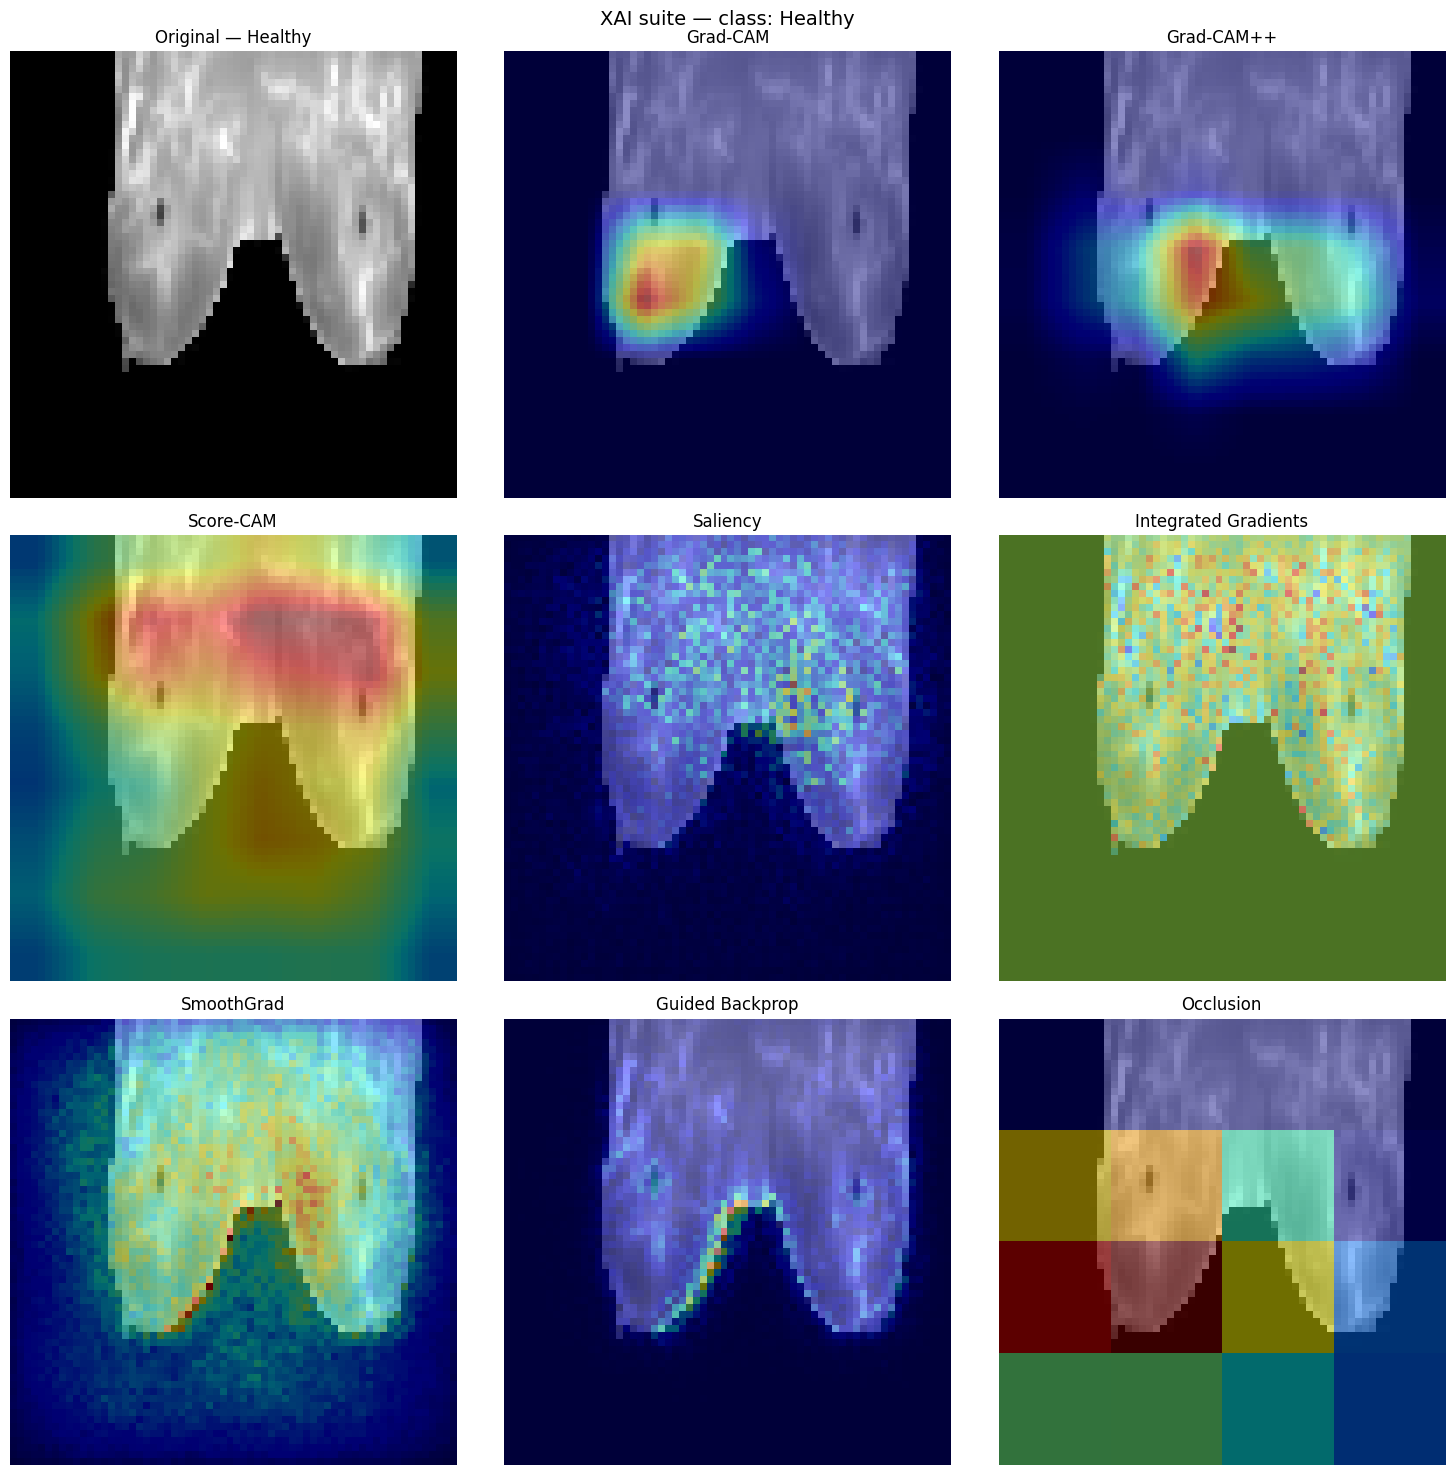

In [38]:
def explain_image(sample_img, class_idx=None, save=True):
    x = prep_input(sample_img)
    if class_idx is None:
        class_idx = int(model.predict(x, verbose=0)[0].argmax())

    results = {
        "Grad-CAM":             grad_cam(model, x, LAST_CONV_LAYER, class_idx),
        "Grad-CAM++":           grad_cam_pp(model, x, LAST_CONV_LAYER, class_idx),
        "Score-CAM":            score_cam(model, x, LAST_CONV_LAYER, class_idx, n_channels=32),
        "Saliency":             vanilla_saliency(model, x, class_idx),
        "Integrated Gradients": integrated_gradients(model, x, class_idx),
        "SmoothGrad":           smoothgrad(model, x, class_idx, n=25),
        "Guided Backprop":      guided_backprop(model, x, class_idx),
        "Occlusion":            occlusion(model, x, class_idx, patch=32, stride=16),
    }

    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    img = prep(sample_img)
    axes.flat[0].imshow(img)
    axes.flat[0].set_title(f"Original — {class_names[class_idx]}")
    axes.flat[0].axis("off")
    for i, (name, heat) in enumerate(results.items(), start=1):
        ax = axes.flat[i]
        ax.imshow(overlay(img, heat))
        ax.set_title(name); ax.axis("off")
    plt.suptitle(f"XAI suite — class: {class_names[class_idx]}", fontsize=14)
    plt.tight_layout()
    if save:
        plt.savefig(XAI_DIR / f"xai_suite_{class_names[class_idx]}.png",
                    dpi=120, bbox_inches="tight")
    plt.show()
    return results, class_idx

_ = explain_image(sample_img)

In [39]:
def predict_and_explain(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img = tf.keras.utils.img_to_array(img) / 255.0
    res, cls = explain_image(img, save=False)
    print(f"Predicted: {class_names[cls]}")
    return res

# Example:
# predict_and_explain("./my_mri.png")

In [40]:
model.save(MODEL_PATH)
(OUT_DIR / "class_names.txt").write_text("\n".join(class_names))
print("Model :", MODEL_PATH.resolve())
print("XAI   :", XAI_DIR.resolve())
print("Outputs:", OUT_DIR.resolve())

Model : C:\Users\MANO\Downloads\Conference\outputs\breast_cnn.keras
XAI   : C:\Users\MANO\Downloads\Conference\outputs\xai
Outputs: C:\Users\MANO\Downloads\Conference\outputs


In [42]:
#https://www.kaggle.com/datasets/raselislambabu/mri-image-brest-cancer/data   dataset link